# Strategy evolution: 10 rounds in a crowded simulated Optibook market

This notebook walks through how the dual-listing strategy evolved from the original `quote_hedge` (v0)
to `evolved` v10, round by round. Each step follows the same loop:

1. **Play a round**: 10 simulated minutes against 12 rival teams plus the exchange's own bots, fully logged.
2. **Read the logs**: `report.md` from `tools/analyze_run.py` (fills by reason, edge at fill, post-fill price moves, order churn, rejects, risk).
3. **Form a hypothesis** and implement it as a *flag* in `strategies/evolved.py` (so every version can be re-run).
4. **Benchmark on held-out markets** (`tools/bench.py`, 8 market seeds never used in a round), plus robustness markets.
5. **Adopt or reject**, then play the next round.

`strategies/quote_hedge.py` is untouched: it is the original. `strategies/evolved.py` holds every version (`version="v0"` ... `"v10"`).

**Read the numbers with this in mind:** the simulator's bots are guesses. The lessons that transfer are the *mechanisms*
(hedge cost decides how tight you can quote, inventory skew vs hedged risk, churn vs queue priority, measuring before assuming),
not the PnL figures.

In [1]:
import json, os, sys, statistics
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
import pandas as pd
import matplotlib.pyplot as plt
from strategies.evolved import VERSIONS, FLAGS_BY_VERSION

# chart styling: one categorical palette in fixed order, recessive grid, text in ink colours
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
def style(ax, title):
    ax.set_facecolor(SURFACE); ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=8)
pd.set_option("display.width", 160)

## 1. The test environment

**Market** (`optisim/`): one stock with a liquid primary listing `ASML` and an illiquid dual listing `ASML_DUAL`, tick 0.1.
Fair value is a random walk with occasional jumps. The exchange runs a tight, deep market maker on the primary, a slow,
wide market maker on the dual (quoting a stale price), random customer orders on both, and a fast informed trader that
picks off stale dual quotes.

**Rivals** (`optisim/crowd.py`): 12 teams modelled on what AI-assisted teams tend to write: about 60% quote-and-hedge
variants, 30% cross-listing arbitrage, 10% "buggy" (quotes but never hedges, panic-dumps at the position limit),
with random settings and loop speeds from 0.1 s to 1 s. Every team has our limits: 100 lots per instrument, 25 orders/s.

**Market types used for robustness**

| market | what is different | why |
|---|---|---|
| `crowded` | the standard round market | main target |
| `crowded_sticky` | the primary market maker keeps its queue position | catches strategies that only work because the bot gives up queue priority |
| `crowded_tight` | primary spread is 1 tick (no price inside it) | catches strategies that assume cheap hedging |
| `crowded_clones` | half the rivals run a copy of our v8 | "everyone's AI converged on the same idea" |

**Rounds vs benchmark.** Round R uses market seed 100+R, which is never used for tuning. Every decision was made on the
benchmark (seeds 0-7). A single round is one noisy sample: round 1 was a lucky 1st place for v0, whose benchmark rank was 7.25/13.

In [2]:
from optisim.crowd import make_crowd
crowd = make_crowd([("ASML", "ASML_DUAL")], 12, 101, None)
pd.DataFrame([{"team": n, "loop (s)": every * 0.1,
               **{k: getattr(s, k) for k in ("edge", "size", "penny", "min_edge") if hasattr(s, k)}}
              for n, s, every, _ in crowd]).fillna("")

,team,loop (s),edge,size,penny,min_edge
0,team00_quote_hedge,0.5,1.0,5.0,True,
1,team01_cross_arb,0.2,,,,2.0
2,team02_cross_arb,0.2,,,,1.0
3,team03_quote_hedge,1.0,1.0,20.0,False,
4,team04_quote_hedge,0.3,0.0,10.0,True,
5,team05_cross_arb,0.3,,,,2.0
6,team06_cross_arb,0.5,,,,1.0
7,team07_quote_hedge,0.1,1.0,10.0,False,
8,team08_quote_hedge,1.0,2.0,5.0,True,
9,team09_buggy,0.5,,5.0,,


## 2. The 10 rounds

In [3]:
res = pd.DataFrame([json.loads(l) for l in open(os.path.join(ROOT, "rounds", "results.jsonl"))])
res["scenario"] = res.get("scenario", pd.Series(dtype=str)).fillna("crowded")
res[["round", "version", "scenario", "rank", "n", "pnl", "best_rival", "best_rival_name", "note"]]

,round,version,scenario,rank,n,pnl,best_rival,best_rival_name,note
0,1,v0,crowded,1,13,10.6,9.40,team07_quote_hedge,baseline: exact copy of quote_hedge
1,2,v1,crowded,10,13,-10.2,43.40,team03_cross_arb,passive hedge inside primary spread
2,3,v2,crowded,1,13,62.8,12.30,team06_quote_hedge,"sticky quotes, quote first, single-leg arb"
3,4,v3,crowded,3,13,31.1,61.69,team01_buggy,price from fair +- (hedge cost + min profit); ...
4,5,v4,crowded,1,13,49.8,7.70,team01_quote_hedge,inventory skew only near position limit
5,6,v6,crowded,1,13,116.8,5.00,team05_cross_arb,"adaptive hedge ladder: touch -> mid -> IOC, to..."
6,7,v7,crowded,1,13,199.2,20.30,team01_cross_arb,exit closes only unhedged delta (wind-down tes...
7,8,v8,crowded,1,13,102.1,6.40,team08_quote_hedge,arb unwind threshold depends on hedge cost; un...
8,9,v9,crowded_clones,1,13,82.6,74.20,team05_clone,half the field are v8 clones; faster 0.1s loop
9,10,v10,crowded_clones,2,13,48.6,56.00,team05_clone,quote size 15


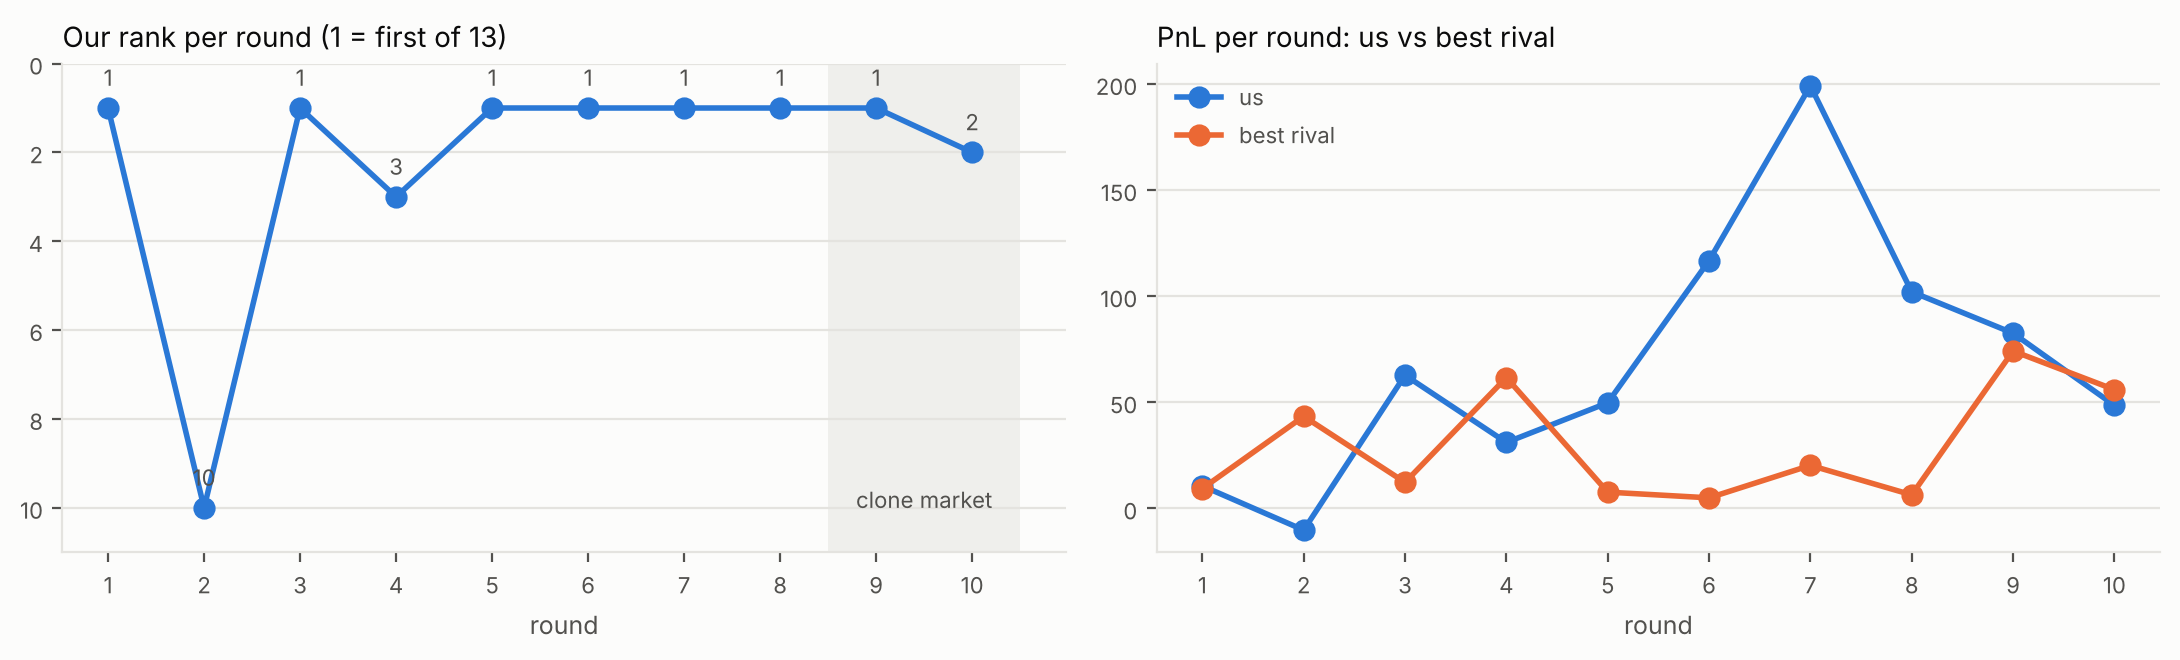

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), facecolor=SURFACE)
ax = axes[0]
ax.plot(res["round"], res["rank"], color=SERIES[0], linewidth=2, marker="o", markersize=7)
for r, k in zip(res["round"], res["rank"]):
    ax.annotate(str(k), (r, k), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=INK2)
ax.set_ylim(res["rank"].max() + 1, 0); ax.set_xticks(res["round"]); style(ax, "Our rank per round (1 = first of 13)")
ax.axvspan(8.5, 10.5, color=GRID, alpha=0.5, linewidth=0); ax.text(9.5, res["rank"].max(), "clone market", ha="center", fontsize=8, color=INK2)
ax = axes[1]
ax.plot(res["round"], res["pnl"], color=SERIES[0], linewidth=2, marker="o", markersize=7, label="us")
ax.plot(res["round"], res["best_rival"], color=SERIES[1], linewidth=2, marker="o", markersize=7, label="best rival")
ax.set_xticks(res["round"]); style(ax, "PnL per round: us vs best rival")
ax.legend(frameon=False, fontsize=8, labelcolor=INK2, loc="upper left")
for a in axes: a.set_xlabel("round", color=INK2, fontsize=9)
fig.tight_layout(); plt.show()

Rounds 1-8 were played on the standard crowded market, rounds 9-10 on the clone market (half the field runs our v8).
Each round's full report and chart are in `rounds/round_XX/`. Because one round is one sample, the version-by-version
sections below quote the **benchmark** numbers (8 held-out markets) that the decisions were based on.

## 3. Versions: what the logs said, what changed, what the benchmark said

In [5]:
rows, prev = [], {}
for name, flags in FLAGS_BY_VERSION:
    rows.append({"version": name, "flags added": ", ".join(f"{k}={v}" for k, v in flags.items()) or "(none)"})
pd.DataFrame(rows)

,version,flags added
0,v0,(none)
1,v1,"passive_hedge=True, hedge_timeout=1.0, max_unh..."
2,v2,"sticky_ticks=1, quote_first=True, arb_single_l..."
3,v3,"cost_quote=True, passive_cost=0.4, min_profit=0.5"
4,v4,skew_start=50
5,v5,touch_secs=0.4
6,v6,"adaptive_touch=True, touch_min_rate=0.35, touc..."
7,v7,(none)
8,v8,arb_cost_aware=True
9,v9,(none)


### v0: the original (exact copy of quote_hedge)

**Strategy.** Quote the dual at (primary best bid - edge, primary best ask + edge), penny the best other quote,
skew both quotes against dual inventory, hedge every fill immediately on the primary with an IOC order, and take crossed
quotes on both legs.

**Round 1 (1st, 10.6 vs 9.4)** looked fine, but the logs showed the problems:
- 1,933 quote inserts and 1,924 cancels for **27** quote fills; 153 orders blocked by our own rate limiter
- hedges paid **-1.00 tick/lot** (-13.3), eating 70% of what quotes earned (+19.1)
- the primary spread was 2 ticks, so there is a price *inside* it

**Benchmark:** mean PnL -4.3, mean rank 7.25/13, 1st in 1/8. Round 1 was luck.

### v1: rest the hedge inside the primary spread

**Change.** If the primary spread is at least 2 ticks, rest the hedge at the mid (inside the spread), where the primary's heavy
customer flow fills it at about zero cost. Cross with IOC only after `hedge_timeout` = 1 s, if more than 30 lots are unhedged,
if the spread is 1 tick, or if the primary is paused.

**Benchmark:** -4.3 -> **6.1** PnL, rank 7.25 -> 5.25. (Timeout 3 s looked slightly better, but within noise; kept 1 s for lower risk.)

**Round 2 (10th, -10.2):** quote fills at **-0.59 ticks** with post-fill moves to -1.87 (stale quotes picked off), 1,851 requotes,
106 throttled orders, and one arb leg **rejected as self-trade** against our own resting hedge, which forced a 33-lot IOC hedge.

### v2: stop the churn, fix the self-trade

**Changes** (benchmarked one at a time):
- `sticky_ticks=1`: keep a resting quote if it is still safe and within 1 tick of the target (keeps queue priority, saves orders)
- `quote_first`: update quotes before hedging/taking, so stale quotes are fixed first
- `arb_single_leg`: take only the scarce dual leg; the hedger lays off the primary leg passively (no IOC cost, no self-trade)
- `budget_reserve`: **no effect**, dropped

**Benchmark:** 6.1 -> **10.7**, rank 5.25 -> 4.12. Without single-leg arb: 7.1; without sticky quotes: 9.1.

**Round 3 (1st, 62.8 vs 12.3):** requotes 1,851 -> 608, throttled 0, quote edge +1.26, hedge cost -0.37/lot (was -1.00).

### v3: price from fair value and the real hedge cost

**Insight.** Our hedge now costs about 0.4 tick; rivals who cross the spread pay about 1. A cheaper hedge means we can quote tighter
than they can afford. A parameter sweep showed `edge=0` (quote at the primary touch) jumps to **43.3** PnL, rank 1.50, 6/8 wins.

**But edge=0 only works because the primary spread is 2 ticks here.** On the 1-tick market it scored **-114**.
So v3 generalises it: `bid = fair - (expected hedge cost + min profit)`, `ask = fair + (...)`, where the hedge cost is
0.4 tick if the hedge can rest inside the spread, else half the spread. It also fixes a bug: the strategy read **our own
resting hedge** as the primary market when pricing quotes.

**Benchmark:** **47.3**, rank 1.62, 5/8 wins. Tight market: -44 (vs -114 for hard-coded edge 0).

**Round 4 (3rd, 31.1):** only two unhedged "buggy" gamblers (max net delta 84 and 64) finished above us, so we were 1st among
risk-controlled teams. Quote markouts are positive (+1.1 to +1.4), so we are not being picked off. Volume became the limit.
A second, deeper quote level was considered and **rejected from the logs**: 99% of dual volume trades at the first price level.

### v4: inventory skew only near the limit

**Log evidence (round 4).** Inventory skew moved our quotes 1-2 ticks off the best price **70% of the time**, while net delta
(the real risk) was non-zero only **7.7%** of the time. The dual position is hedged on the primary, so skewing for it protects
against a risk we no longer hold, and costs fills.

**Change.** `skew_start=50`: skew only when |dual position| > 50 (protects the position limit).

**Benchmark:** 47.3 -> **58.3**, rank 1.38. Tight market -44 -> -32. 24 rivals: 30.6 -> 39.3.

**Round 5 (1st, 49.8 vs 7.7):** quote volume doubled. Next leak: resting hedges at mid cost -0.27/lot (-17.5 vs +32.1 from quotes).

### v5 (benchmark only): hedge ladder, and a simulator artifact

**Change.** Hedge in stages: rest **at the touch** for 0.4 s (earn the half spread if flow comes), then at mid, then IOC.

**Benchmark:** 58.3 -> **91.7**. Suspiciously large. Hypothesis: the simulated primary market maker cancels and re-sends every
step, which puts it at the back of the queue and hands us the front. On `crowded_sticky` (market maker keeps its queue spot)
v5 scored **59.1 vs v4 60.9**: the gain was mostly an artifact. **Not played in a round.**

### v6: adaptive hedge ladder

**Change.** Keep the ladder, but **measure** it: track how often the touch hedge actually fills (from our own position changes),
skip the touch step when the rate drops below 35%, and re-test it every 30 s.

**Benchmark:** crowded **87.7** (keeps most of v5's gain where touch hedging works), sticky 62.3 (no harm where it doesn't).

**Round 6 (1st, 116.8 vs 5.0):** hedges now *earn* +0.58/lot. New leak: closing +62 dual / -62 primary at the end cost **-18.8**,
because the dual book is thin.

### v7: exit rule (wind-down rejected)

**Tried:** `wind_down_secs=60`: quote only the inventory-reducing side in the final minute. **Worse** (-1 to -4 PnL): one-sided
quoting gives up more than it saves. Rejected.

**Adopted (runner, not strategy):** exit mode `net`: on stop, close only the *unhedged* delta. A hedged pair has no price risk.
Worth **+5.5 PnL** per session vs closing everything (benchmarked with exit costs charged).
Whether you may finish holding a hedged pair depends on the competition's scoring: check the brief.

**Round 7 (1st, 199.2 vs 20.3)**, round 8 below.

### v8: cost-aware arbitrage

**Log evidence (tight-market experiments).** In a 1-tick primary market, the arb unwound inventory at **zero edge**
(about 2,200 lots), while every hedge paid half a tick. Unwinds could also overshoot through zero into new zero-edge positions.

**Change.** An unwind may only use the zero-edge rule when the hedge can rest inside a >=2 tick spread; otherwise it needs a full
tick. Unwind volume is capped at the inventory.

**Benchmark:** tight market **-34.7 -> +3.2** (rank 8.0 -> 4.25). Crowded: same PnL, rank 1.12, 7/8 wins, max delta 30 -> 24.
Regression checks: hard market (2 stocks, jumps, primary paused) v0 295 -> v8 615; 24 rivals: rank 12 -> 1.83.

**Round 8 (1st, 102.1 vs 6.4).**

### v9: when everyone copies you

**Test.** Half the field runs v8 (settings jittered). Our rank drops to **3.25**, 1st in 2/8: identical strategies split the
same flow at the same price, so the queue decides.

**Tried:** `queue_jump`: step 1 tick ahead of a queue, betting that the (now positive) hedge edge pays for the zero quote edge.
**Worse everywhere** (clones 43.9 -> 24.5, crowded 87.5 -> 66.1). Rejected.

**Adopted:** a faster loop (execution, not logic). Against clones: 0.1 s loop rank **2.38**, 0.2 s 3.25, 0.5 s 4.12.

**Round 9 (clone market, 1st, 82.6 vs 74.2)**: a narrow win.

### v10: size

**Log evidence (round 9).** The best clone traded 1,518 lots vs our 1,162.

**Change.** Quote size 15 (from 10). It wins on **both** the clone market (58.4 -> 62.1) and the standard market (91.1 -> 98.0)
at a 0.1 s loop. A longer hedge timeout was mixed and not adopted.

**Round 10 (clone market, 2nd, 48.6 vs 56.0).** Against copies of yourself it is close to a coin flip. That is the honest end state.

**Caveat from the final evaluation (section 5, 0.2 s loop):** size 15 is only marginal: +2.7 standard, +0.9 clones,
-1.3 sticky, and **-5.6 on the 1-tick market** (bigger size = more inventory when hedging is expensive). Treat size as a
setting to raise live (settings file) when the primary spread is >= 2 ticks and post-fill moves are positive, not as a
fixed improvement. v8 with size 10 is the safer default if the market looks tight.

## 4. Rejected ideas

| idea | evidence | verdict |
|---|---|---|
| reserve part of the order budget for hedges | benchmark: identical results | dropped (no effect) |
| hard-code edge 0 | +43 on the standard market, **-114** on the 1-tick market | replaced by the cost model (v3) |
| second, deeper quote level | 99% of dual volume trades at the first level | not built |
| hedge at the touch, always (v5) | gain disappears when the market maker keeps its queue spot | made adaptive (v6) |
| wind down inventory in the last minute | -1 to -4 PnL | rejected |
| jump ahead of a queue at zero quote edge | worse on every market | rejected |
| longer hedge timeout | mixed across markets | not adopted |

## 5. Final evaluation: every version on every market

8 held-out markets per cell, 10 minutes each, 12 rivals, exit = close unhedged delta only, same 0.2 s loop for every version
(so v9's speed gain is not included; v7 and v9 equal v6 and v8 in logic and are omitted).

In [6]:
ev = json.load(open(os.path.join(ROOT, "rounds", "eval_versions.json")))
df = pd.DataFrame(ev["rows"])
order = [v for v, _ in FLAGS_BY_VERSION if v in set(df.version)]
scen = ["crowded", "crowded_sticky", "crowded_tight", "crowded_clones"]
pnl = df.pivot_table(index="version", columns="scenario", values="pnl", aggfunc="mean").loc[order, scen].round(1)
rank = df.pivot_table(index="version", columns="scenario", values="rank", aggfunc="mean").loc[order, scen].round(2)
first = (df.assign(first=df["rank"] == 1).pivot_table(index="version", columns="scenario", values="first", aggfunc="mean")
         .loc[order, scen] * 100).round(0)
print("Mean PnL"); display(pnl)
print("Mean rank (of 13)"); display(rank)
print("% of markets finished 1st"); display(first)

Mean PnL


scenario,crowded,crowded_sticky,crowded_tight,crowded_clones
version,,,,
v0,-4.3,-1.8,-15.0,-6.8
v1,6.1,7.4,-12.5,-0.9
v2,10.7,13.1,-36.6,0.7
v3,47.3,53.9,-44.8,21.7
v4,58.3,60.8,-32.0,24.9
v5,91.7,59.0,-34.7,45.2
v6,87.6,62.2,-34.7,43.6
v8,87.5,61.9,3.2,44.0
v10,90.2,60.6,-2.4,44.9


Mean rank (of 13)


scenario,crowded,crowded_sticky,crowded_tight,crowded_clones
version,,,,
v0,7.25,6.00,8.38,10.00
v1,5.25,3.00,8.25,8.88
v2,4.12,2.00,8.88,8.75
v3,1.62,1.38,9.00,4.62
v4,1.38,1.38,7.62,4.25
v5,1.25,1.38,8.00,2.88
v6,1.25,1.50,8.00,2.88
v8,1.12,1.25,4.25,3.25
v10,1.25,1.50,5.38,3.12


% of markets finished 1st


scenario,crowded,crowded_sticky,crowded_tight,crowded_clones
version,,,,
v0,12.0,12.0,0.0,0.0
v1,25.0,38.0,0.0,0.0
v2,25.0,62.0,0.0,0.0
v3,62.0,88.0,0.0,12.0
v4,62.0,88.0,12.0,25.0
v5,75.0,88.0,0.0,38.0
v6,75.0,75.0,0.0,38.0
v8,88.0,88.0,12.0,25.0
v10,75.0,75.0,0.0,38.0


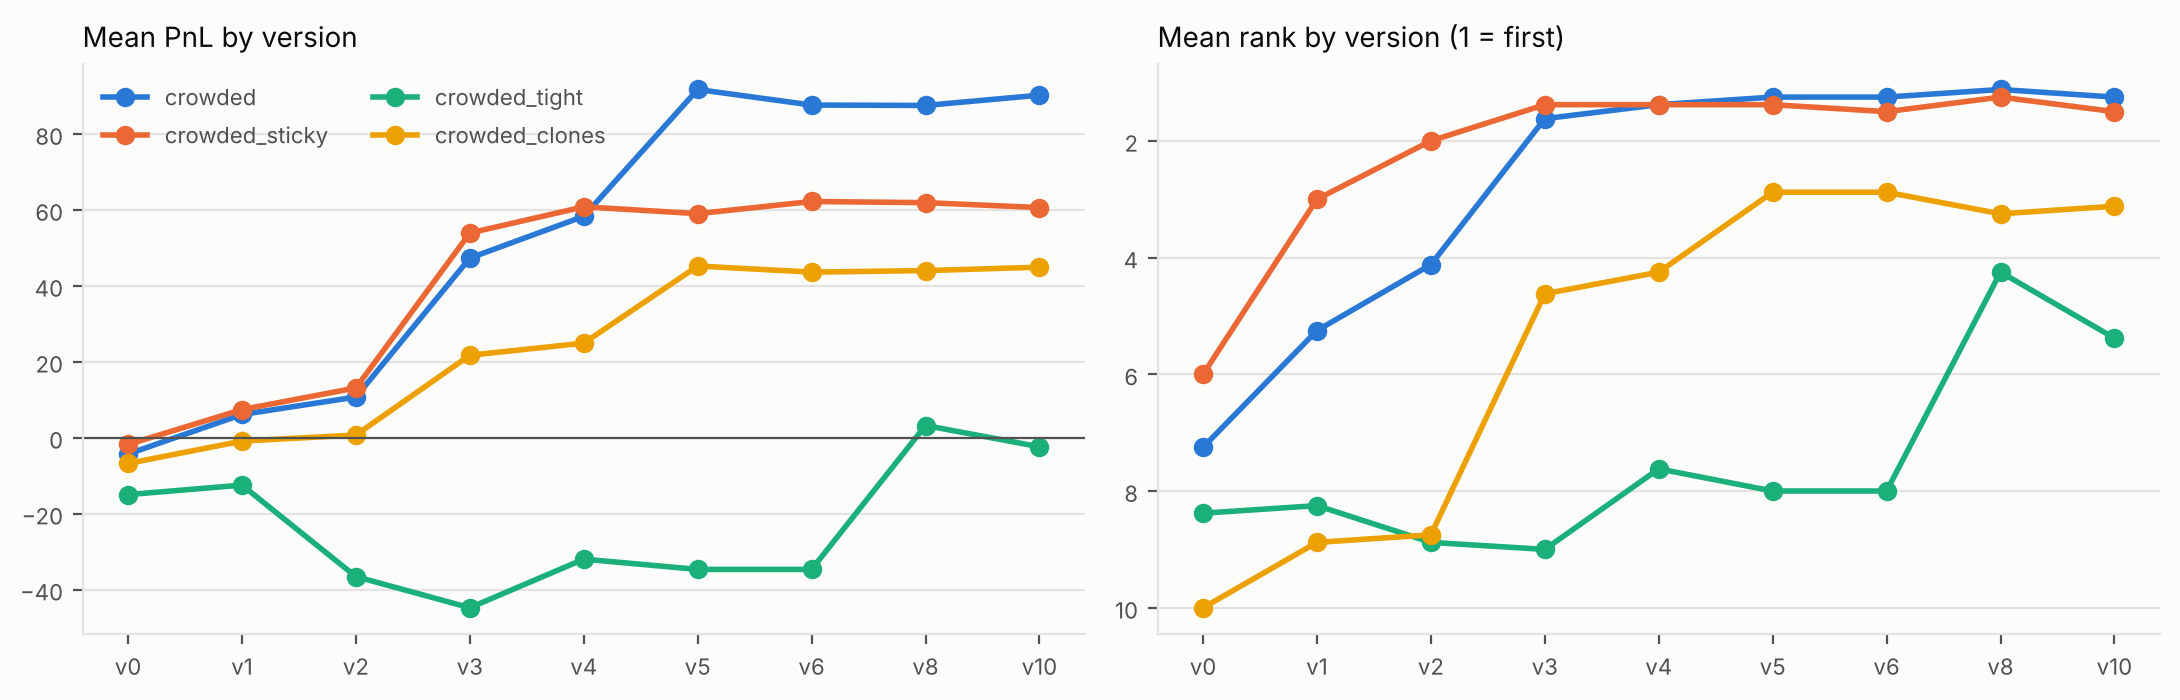

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURFACE)
x = range(len(order))
for k, sc in enumerate(scen):
    axes[0].plot(x, pnl[sc].values, color=SERIES[k], linewidth=2, marker="o", markersize=6, label=sc)
    axes[1].plot(x, rank[sc].values, color=SERIES[k], linewidth=2, marker="o", markersize=6, label=sc)
axes[0].axhline(0, color=INK2, linewidth=0.8)
style(axes[0], "Mean PnL by version"); style(axes[1], "Mean rank by version (1 = first)")
axes[1].invert_yaxis()
for a in axes:
    a.set_xticks(list(x)); a.set_xticklabels(order)
axes[0].legend(frameon=False, fontsize=8, labelcolor=INK2, ncol=2, loc="upper left")
fig.tight_layout(); plt.show()

In [8]:
# who still beats the final version? rank among ALL rivals vs among risk-controlled rivals (max |net delta| <= 40)
last = order[-1]
d = df[df.version == last]
pd.DataFrame({"mean rank (all rivals)": d.groupby("scenario")["rank"].mean().round(2),
              "mean rank (risk-controlled rivals)": d.groupby("scenario")["rank_vs_hedged"].mean().round(2),
              "max |net delta| (ours)": d.groupby("scenario")["max_abs_net_delta"].max()}).loc[scen]

,mean rank (all rivals),mean rank (risk-controlled rivals),max |net delta| (ours)
scenario,,,
crowded,1.25,1.00,24
crowded_sticky,1.50,1.00,30
crowded_tight,5.38,5.12,15
crowded_clones,3.12,2.75,30


## 6. Lessons that should transfer to the real event

1. **Hedge cost sets how tight you can quote.** The biggest single gain came from making hedging cheaper (v1-v3), then
   pricing quotes off that cost. Measure the primary spread on the day: if there is room inside it, rest the hedge there.
2. **Don't protect against risk you've already hedged.** Inventory skew on a hedged position cost 20% of PnL (v4).
3. **Churn is expensive twice:** it burns the order budget (delaying hedges and cancels) and throws away queue priority (v2).
4. **Rule-of-thumb parameters encode a market.** "Unwind at zero edge" and "edge 0" were right for one spread and wrong for
   another (v3, v8). Derive thresholds from measured costs instead.
5. **Big gains deserve suspicion.** v5's +33 PnL came largely from a simulator quirk. Testing on a market where the quirk
   is removed caught it, and the measured, adaptive version (v6) kept the real part.
6. **When everyone converges on the same idea, execution decides:** loop speed and queue priority (v9). Keep the hot loop
   lean on the day: no prints, recorder every N loops if it is slow, short period.
7. **Unhedged gamblers will sometimes top the leaderboard.** We beat every risk-controlled rival in nearly all markets.
   Beating a lucky gambler would mean taking the same risk; Optiver also judges risk management.

**On the day:** start with `run_live.py --observe`, analyse, then run `evolved` (v10) with the settings file open.
The monitor shows the signals used here: hedge edge, quote edge, post-fill moves, others at our price, churn and throttling.

## 7. Reproduce

```bash
python tools/round.py 11 --version v10                       # play another round (seed 111), report in rounds/round_11
python tools/bench.py v8 v10 --scenario crowded_clones --every 1 --exit net
python tools/eval_versions.py                                # rebuild the table in section 5 (~10 min)
python run_live.py --sim crowded --strategy evolved -p version=v10 --minutes 10   # full logged run
```